# How does a higher-order solver compare? RK45 against the engine's Forward Euler

**Question:** The engine integrates the SIR equations with Forward Euler. How much more accurate is the standard higher-order solver, Dormand-Prince RK45, on the same cases, at what cost in evaluations of the right-hand side, and what would it change in the numbers the example reports?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebook 02 of this topic
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can run the standard higher-order solver of the Python scientific stack, SciPy's RK45, on the same SIR system as the engine, use a second, independent solver as the truth, and compare the two methods by error against the step size and by error against cost. You see why a method of higher order changes the trade between accuracy and work, and what the engine's choice of Forward Euler costs in the example.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 scipy==1.18.1
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

SciPy is the pinned reference implementation of the published solvers here: the product's own method stays the engine. The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import derivatives, simulate

for name in ("numpy", "matplotlib", "scipy"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2
scipy 1.18.1


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

## Method

The comparison needs the engine's own side first, taken from the earlier notebooks. `simulate` of `data-pipeline/pipeline/model/sir.py` is Forward Euler at a quarter-day step: it evaluates the right-hand side of the SIR system once per step, so over 160 days its cost is 640 evaluations, and its error is first order in the step. The cell runs it on the epidemic case and keeps its time grid, which every other solver will be asked to answer on.

The legacy `attack_rate` field means removed fraction R(T)/N. Ever-infected fraction by T is [I(T)+R(T)]/N; they nearly coincide for this completed epidemic case, not for an arbitrary horizon.

In [2]:
# the engine on the epidemic case: its number of steps, which is also its number of right-hand side evaluations
p = params_of("EX02_epidemic")
euler = simulate(p)
grid = np.array(euler.t)
print(f"steps: {len(euler.t) - 1}, evaluations: {len(euler.t) - 1}")
print(f"peak {euler.peak_I:.0f}, on day {euler.t_peak:.2f}, removed fraction {euler.attack_rate:.6f}")

steps: 640, evaluations: 640
peak 27345, on day 24.25, removed fraction 0.923654


## Comparison

The standard method for non-stiff ordinary differential equations is an embedded Runge-Kutta pair. Dormand and Prince (1980) built the pair behind RK45: it advances with a fifth-order formula, compares it with a fourth-order one to estimate the local error, and uses that estimate to choose the next step, so the user sets a tolerance and not a step. A step costs six evaluations of the right-hand side. Hairer, Norsett and Wanner (1993) develop the theory and the eighth-order DOP853 method that this notebook uses as the truth. SciPy implements both in `solve_ivp` (Virtanen et al., 2020); version 1.18.1 is the pinned reference implementation here.

The SIR right-hand side, which the solver needs as a function, is `derivatives` of `data-pipeline/pipeline/model/sir.py`: the same function the engine takes its Euler steps from, so both methods integrate one statement of the model and the notebook defines none. The next cell solves the epidemic case with DOP853 at a tolerance of $10^{-12}$ and prints the cost and the numbers that fix the truth.

In [3]:
# a reference course from an eighth-order solver at 1e-12, on the engine's own right-hand side
y0 = [p.N - p.I0, p.I0, 0.0]
par = (p.beta, p.gamma, p.N)
reference = solve_ivp(derivatives, (0, p.days), y0, args=par, method="DOP853", t_eval=grid, rtol=1e-12, atol=1e-9)
ref_i = reference.y[1]
print(f"reference: {reference.nfev} evaluations, peak {ref_i.max():.2f}", end=", ")
print(f"final R/N {reference.y[2, -1] / p.N:.6f}")

reference: 1610 evaluations, peak 26867.38, final R/N 0.920487


The reference needed 1610 evaluations to hold $10^{-12}$ and puts the peak at 26867.38 people on the engine's grid and the final share at 0.920487, the value the final-size relation gave in the last topic. Two independent routes to the same number are as much confirmation as the example can ask for. Now RK45 at four tolerances, from the SciPy default of $10^{-3}$ down to $10^{-8}$. The cell reports, for each, the evaluations it used and the largest error of its infected curve against the reference as a share of the population, with the engine's Euler run on the same terms.

In [4]:
# Dormand-Prince RK45 at four tolerances, and the largest error of each course against the reference
errors = {"Euler": np.max(np.abs(np.array(euler.I) - ref_i)) / p.N}
costs = {"Euler": len(euler.t) - 1}
for rtol in (1e-3, 1e-4, 1e-6, 1e-8):
    run = solve_ivp(derivatives, (0, p.days), y0, args=par, method="RK45", t_eval=grid, rtol=rtol, atol=1e-6)
    errors[f"RK45 {rtol:g}"] = np.max(np.abs(run.y[1] - ref_i)) / p.N
    costs[f"RK45 {rtol:g}"] = run.nfev
for label in errors:
    print(f"{label:12s} {costs[label]:5d} evaluations   max error {errors[label]:.2e}")
# Extrapolated work is a first-order assumption, not an executed solve.
for target in ("RK45 0.0001", "RK45 1e-06"):
    implied = costs["Euler"] * errors["Euler"] / errors[target]
    print(f"heuristic Euler evaluations for {target}: {implied:.0f}")

Euler          640 evaluations   max error 2.01e-02
RK45 0.001     200 evaluations   max error 1.93e-03
RK45 0.0001    284 evaluations   max error 6.88e-05
RK45 1e-06     554 evaluations   max error 5.37e-07
RK45 1e-08    1028 evaluations   max error 7.46e-09
heuristic Euler evaluations for RK45 0.0001: 186969
heuristic Euler evaluations for RK45 1e-06: 23963914


RK45 at the loosest tolerance, 200 evaluations, already makes an error of 1.93e-03, ten times smaller than the engine's 2.01e-02 at 640. At $10^{-6}$ it uses 554 evaluations, 13 percent fewer than the engine, and its error is 5.37e-07, about 37000 times smaller. The comparison is not yet at the same footing: RK45 chooses its own steps. To compare the methods at an equal step the next cell sweeps $h$ from 2 down to 0.125 days, runs Euler at each, and forces RK45 to take exactly that step by capping the step size and setting an absurdly loose tolerance, so that every step is accepted. It prints both errors and the slope of each on log axes.

In [5]:
# the error against the step: Euler at five steps, and RK45 forced to take exactly the same steps
steps = [2.0, 1.0, 0.5, 0.25, 0.125]
euler_error = []
rk_error = []
for h in steps:
    g = np.arange(0, p.days + 1e-9, h)
    exact = solve_ivp(derivatives, (0, p.days), y0, args=par, method="DOP853", t_eval=g, rtol=1e-12, atol=1e-9).y[1]
    euler_error.append(np.max(np.abs(np.array(simulate(p, h).I) - exact)) / p.N)
    cap = dict(first_step=h, max_step=h, rtol=1e6, atol=1e6)
    fixed = solve_ivp(derivatives, (0, p.days), y0, args=par, method="RK45", t_eval=g, **cap)
    rk_error.append(np.max(np.abs(fixed.y[1] - exact)) / p.N)
    e1, e2 = euler_error[-1], rk_error[-1]
    print(f"h = {h:5.3f}  Euler {e1:.2e}  RK45 {e2:.2e}  Euler / RK45 {e1 / e2:.1e}")
slope_euler = np.polyfit(np.log(steps), np.log(euler_error), 1)[0]
slope_rk = np.polyfit(np.log(steps), np.log(rk_error), 1)[0]
print(f"slopes of log error against log step Euler {slope_euler:.2f}, RK45 {slope_rk:.2f}")

h = 2.000  Euler 1.35e-01  RK45 8.34e-06  Euler / RK45 1.6e+04
h = 1.000  Euler 7.54e-02  RK45 3.76e-07  Euler / RK45 2.0e+05
h = 0.500  Euler 3.96e-02  RK45 1.40e-08  Euler / RK45 2.8e+06
h = 0.250  Euler 2.01e-02  RK45 4.75e-10  Euler / RK45 4.2e+07
h = 0.125  Euler 1.01e-02  RK45 1.55e-11  Euler / RK45 6.5e+08
slopes of log error against log step Euler 0.94, RK45 4.77


The next cell draws the two errors against the step on logarithmic axes.

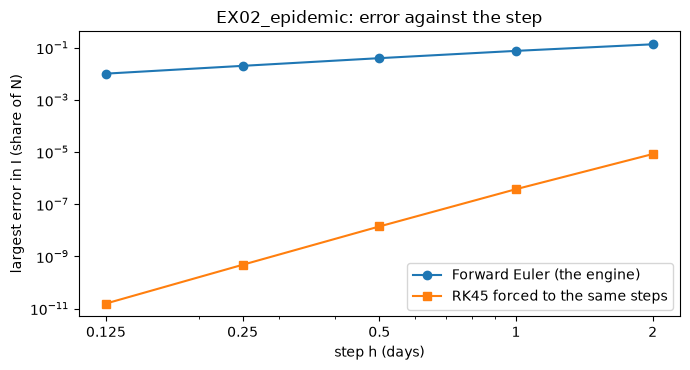

In [6]:
# draw the two errors against the step on log axes
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(steps, euler_error, "o-", label="Forward Euler (the engine)")
ax.loglog(steps, rk_error, "s-", label="RK45 forced to the same steps")
ax.set_xticks(sorted(steps), [f"{value:g}" for value in sorted(steps)])
ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.set_xlabel("step h (days)")
ax.set_ylabel("largest error in I (share of N)")
ax.set_title("EX02_epidemic: error against the step")
ax.legend()
fig.tight_layout()
plt.show()

Both errors fall on straight lines, with very different slopes: 0.94 for Euler, close to its theoretical 1, and 4.77 for RK45, close to its theoretical 5. Halving the step halves Euler's error and divides RK45's by about 30. At the engine's own step of 0.25 days the two methods differ by a factor of 4.2e+07. The picture is flattering to RK45 because a step of RK45 costs six evaluations and one of Euler costs one, a difference the plot hides; the next figure charges the cost.

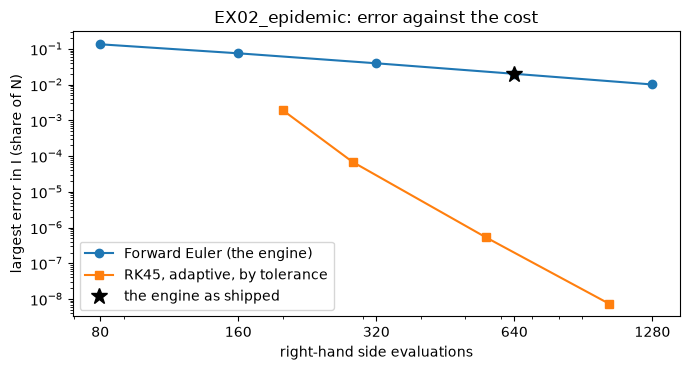

In [7]:
# draw the error against the number of right-hand side evaluations: Euler at its steps, adaptive RK45 at its tolerances
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog([p.days / h for h in steps], euler_error, "o-", label="Forward Euler (the engine)")
adaptive = [k for k in costs if k != "Euler"]
ax.loglog([costs[k] for k in adaptive], [errors[k] for k in adaptive], "s-", label="RK45, adaptive, by tolerance")
ax.plot([costs["Euler"]], [euler_error[steps.index(0.25)]], "k*", markersize=12, label="the engine as shipped")
ax.set_xticks([80, 160, 320, 640, 1280], ["80", "160", "320", "640", "1280"])
ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.set_xlabel("right-hand side evaluations")
ax.set_ylabel("largest error in I (share of N)")
ax.set_title("EX02_epidemic: error against the cost")
ax.legend()
fig.tight_layout()
plt.show()

Evaluation count is not elapsed time. The Euler curve passes through its 640-evaluation default star and continues to 1280 evaluations: the star is an interior configuration, not the curve endpoint. Adaptive RK45 points correspond to the tolerances identified in the table. The heuristic estimate of roughly 24 million Euler evaluations concerns rtol=10^-6, the third listed RK45 point; rtol=10^-4, the second point, implies about 187 thousand. Neither is work actually executed or a latency measurement. The comparison holds the equation and numerical protocol fixed but establishes no corresponding result for stiff systems or other state scales.

The last cell runs the same comparison on every case with infected people, at the engine's step for Euler and at $10^{-6}$ for RK45, and prints the error of the peak for each. It answers whether the epidemic case is typical.

In [8]:
# the same comparison on every case that has infected people: the peak error of the engine and of RK45 at rtol 1e-6
print(f"{'case':18s} {'Euler peak err':>12s} {'RK45 peak err':>12s} {'evals':>8s}")
for case_id in CASES:
    q = params_of(case_id)
    if q.I0 == 0:
        continue
    own = simulate(q)
    qg = np.array(own.t)
    q0, qp = [q.N - q.I0, q.I0, 0.0], (q.beta, q.gamma, q.N)
    truth = solve_ivp(derivatives, (0, q.days), q0, args=qp, method="DOP853", t_eval=qg, rtol=1e-12, atol=1e-9).y[1]
    rk = solve_ivp(derivatives, (0, q.days), q0, args=qp, method="RK45", t_eval=qg, rtol=1e-6, atol=1e-6)
    err_euler = own.peak_I / truth.max() - 1
    err_rk = rk.y[1].max() / truth.max() - 1
    print(f"{case_id:18s} {err_euler:+12.2e} {err_rk:+12.2e} {rk.nfev:8d}")

case               Euler peak err RK45 peak err    evals
EX01_subcritical      +0.00e+00    +0.00e+00      212
EX02_epidemic         +1.78e-02    +1.63e-07      554
EX03_fast_burn        +3.34e-02    +2.83e-07      620
EX04_slow_spread      +3.89e-03    +1.06e-06      176


### Sensitivity: solving accurately is different from sampling a peak

Dormand-Prince forms two estimates from shared stage derivatives $k_j=f(t_j,y_j)$. The fifth-order estimate advances the solution; its fourth-order companion estimates local error (Dormand and Prince, 1980). With method coefficients $b_j$ and $\widehat b_j$, the pair can be written as

$$y_{n+1}^{(5)}=y_n+h\sum_j b_jk_j,\qquad e_n=h\sum_j(b_j-\widehat b_j)k_j.$$

SciPy scales each component's estimated error using its absolute tolerance and its current magnitude:

$$w_i=\operatorname{atol}_i+\operatorname{rtol}|y_i|,\qquad \hbox{scaled error}_i=e_i/w_i.$$

Here $y_i$ and `atol` have units of people, while `rtol` is dimensionless. This error control concerns accepted integration steps, not an uncertainty band on the outbreak or a direct upper bound on the eventual peak error. A single scalar tolerance also treats a compartment of fifty people differently from one of a hundred thousand. Six new derivative evaluations per ordinary accepted RK45 step benefit from derivative reuse; startup and rejected steps explain why the total `nfev` need not be exactly six times a reported point count. Requesting more `t_eval` points usually samples interpolation rather than forcing the same number of internal steps.

The next cell holds the equation, initial state and tight RK45 tolerance fixed, and changes only the reporting interval. A dense DOP853 reference estimates the continuous peak on a much finer reporting grid. If a coarse request skips the maximum, excellent local error control cannot recover it from a simple maximum of the returned samples. This is a measurement-definition issue on top of integration error, particularly relevant to a product that exports a decimated trace.

interval=0.25, peak=26867.38, nfev=2030
interval=2.00, peak=26746.05, nfev=2030
interval=8.00, peak=26746.05, nfev=2030


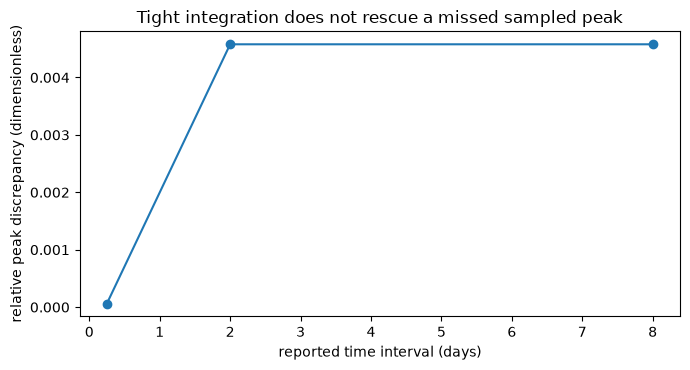

In [9]:
# Keep integration tolerance fixed while changing only requested reporting times.
dense = solve_ivp(derivatives, (0, p.days), y0, args=par, method="DOP853",
                  rtol=1e-12, atol=1e-9, dense_output=True)
dense_peak = dense.sol(np.linspace(0, p.days, 40961))[1].max()
report_intervals = [0.25, 2.0, 8.0]
sampling_error = []
for interval in report_intervals:
    report_grid = np.arange(0, p.days + 1e-9, interval)
    reported = solve_ivp(derivatives, (0, p.days), y0, args=par, method="RK45",
                         t_eval=report_grid, rtol=1e-9, atol=1e-9)
    sampling_error.append(abs(reported.y[1].max() / dense_peak - 1))
    print(f"interval={interval:.2f}, peak={reported.y[1].max():.2f}, nfev={reported.nfev}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(report_intervals, sampling_error, "o-")
ax.set_xlabel("reported time interval (days)")
ax.set_ylabel("relative peak discrepancy (dimensionless)")
ax.set_title("Tight integration does not rescue a missed sampled peak")
fig.tight_layout()
plt.show()

The new figure isolates a source of peak discrepancy that the earlier work-versus-error comparison holds fixed. Coarsening the reporting grid can miss the continuous maximum even when the same tight solver does essentially the same internal work. These values are deterministic sampling effects, not repeated-trial uncertainty or timings. The fine dense reference still has interpolation and finite-grid error, so it is an accurate numerical comparator rather than an exact oracle. A downstream consumer should preserve the full-resolution summary instead of recomputing the peak from a compact plotting trace.

### Use it on your own data

Admit rates, population, initial infections and horizon through the params-record boundary before constructing the initial state. Give `solve_ivp` the product's `derivatives`, a time interval in days, `y0=[N-I0,I0,0]`, and `args=(beta,gamma,N)`. Choose output times independently of the tolerance and inspect `success` and `message` before using a returned curve. For a different compartment scaling, select `atol` in those same state units; copying a tolerance expressed in people onto population fractions changes the numerical question. Use a refined reference or an applicable independent relation to determine whether the chosen accuracy suffices. This notebook compares numerical work through `nfev`; it provides no latency ranking, stochastic confidence interval or evidence about interventions in a real community.

## Results

**Answer:** On the epidemic case the engine's Forward Euler, at 640 evaluations, makes a largest error of 2.01e-02 of the population in the infected curve, against 1.93e-03 for RK45 at its default tolerance with 200 evaluations and 5.37e-07 for RK45 at $10^{-6}$ with 554 evaluations: RK45 is about 37000 times more accurate for 13 percent less work. At equal steps Euler's error scales with slope 0.94 and RK45's with slope 4.77, so at the engine's step of 0.25 days they differ by a factor of 4.2e+07. On the peak, Euler is high by 1.78e-02 for the epidemic case and 3.34e-02 for the fast burn, while RK45 is within 1.06e-06 on every case. Reproducing the example's numbers with RK45 would move the epidemic case's peak from 27345 down to about 26867 people and its removed fraction from 0.923654 to 0.920487.

The result is for a smooth, non-stiff system, and the cost count of evaluations is not a timing: a solver's overhead per call matters too, which a pure-Python loop like the engine's hides. The engine keeps Forward Euler by design, a one-line integrator that its TypeScript twin in the web port reproduces step for step; this notebook measures what that choice costs, and the answer is a peak between 0.4 and 3.3 percent high, depending on the case.

## Summary

- RK45 (Dormand and Prince) with a tolerance of $10^{-6}$ is about 37000 times more accurate than the engine's Euler step on the epidemic case, with 13 percent fewer evaluations.
- At equal steps the error slopes are 0.94 for Euler and 4.77 for RK45: orders 1 and 5.
- The advantage holds on all four cases with infected people: the peak error falls from up to 3.3 percent to about 1e-06.
- The engine's Forward Euler is a design choice for simplicity and parity with the web port; its cost is a peak 0.4 to 3.3 percent high.
- Next: topic 02 asks when an outbreak takes off and how large it gets.

## References

- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- Dormand, J. R. and Prince, P. J. (1980). A family of embedded Runge-Kutta formulae. Journal of Computational and Applied Mathematics. https://doi.org/10.1016/0771-050X(80)90013-3
- Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. Nature Methods. https://doi.org/10.1038/s41592-019-0686-2
- SciPy, https://pypi.org/project/scipy/ (pinned in `notebooks/requirements.txt`).
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).
- SciPy solve_ivp API: https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
